# AML Baseline Training on IBM's Synthetic Dataset

Baseline notebook to detect money laundering using transaction-level and simple entity features

What this does:
- Loads mini CSV, cleans types, derives basic features
- Time-based split (avoid leakage)
- Entity aggregates from train only, merged into test
- Model: LightGBM for now, try random forrest
- Evaluation: PR-AUC, precision/recall at alert budget; top-k alerts table



In [1]:
# All the imports ()
import importlib, subprocess, sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import average_precision_score, precision_recall_curve, classification_report
from sklearn.ensemble import RandomForestClassifier

import lightgbm as lgb

import joblib


### Data Loading

In [2]:
# Configuration
DATA_PATH = '../Datasets/trans_3000p2_list.csv' # 45 million row (use less?)
TARGET_COL = 'Is Laundering'
RANDOM_STATE = 42
ALERT_RATE = 0.001 # 0.1% of scored transactions flagged

print('Data path:', DATA_PATH)


Data path: ../Datasets/trans_3000p2_list.csv


In [ ]:
#~1:45

# Load and basic cleaning
df = pd.read_csv(DATA_PATH)
# Strip whitespace from column names and string values
df.columns = df.columns.str.strip()
for c in df.columns:
    if df[c].dtype == 'object':
        df[c] = df[c].astype(str).str.strip()

# Set timestamp to usable date and amounts to numerics (more efficient)
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
for amt_col in ['Amount Received', 'Amount Paid']:
    df[amt_col] = pd.to_numeric(df[amt_col], errors='coerce')

# Drop rows with missing essentials (should be none)
df = df.dropna(subset=['Timestamp', 'Amount Received', 'Amount Paid', TARGET_COL]).copy()
df[TARGET_COL] = pd.to_numeric(df[TARGET_COL], errors='coerce').fillna(0).astype(int)

# Removed sorting due to huggggeee performance issue

print(df.head(3))
print('Rows:', len(df), '| positives:', int((df[TARGET_COL]==1).sum()))


### Feature Engineering @ Transaction Level

In [ ]:
#~12.5

###########################################
# Feature engineering (transaction level)
# Added:
#   Spread between paid and receieved
#   Is it a change in currency
#   Is it from the same bank 
#   Is it a transfer to own account
#   hour, day of week, weekend or not
###########################################
def build_tx_features(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out['fx_spread'] = out['Amount Paid'] - out['Amount Received']
    out['is_cross_cur'] = (out['Receiving Currency'] != out['Payment Currency']).astype(int)
    out['same_bank'] = (out['From Bank'] == out['To Bank']).astype(int)
    out['self_transfer'] = (out['Account'] == out['To Account']).astype(int)
    out['hour'] = out['Timestamp'].dt.hour
    out['dow'] = out['Timestamp'].dt.dayofweek
    out['is_weekend'] = out['dow'].isin([5, 6]).astype(int)
    return out

df = build_tx_features(df)
df.head(10)


In [ ]:
#~30

# Time based split: train = first 80%, test = last 20% by Timestamp (does NOT require the sorting I commented out btw, by quantile)
required_feats = ['fx_spread','is_cross_ccy','same_bank','self_transfer','hour','dow','is_weekend']
if any(f not in df.columns for f in required_feats):
    try:
        df = build_tx_features(df)
    except Exception as _e:
        pass
split_time = df['Timestamp'].quantile(0.80) # <- split here
train_df = df[df['Timestamp'] <= split_time].copy()
test_df  = df[df['Timestamp'] >  split_time].copy()

print('Train rows:', len(train_df), '| Test rows:', len(test_df))
print('Positives (train/test):', int(train_df[TARGET_COL].sum()), int(test_df[TARGET_COL].sum()))


In [ ]:
# ~2:30

# For reffence on agg: https://www.w3schools.com/python/pandas/ref_df_agg.asp
# Entity aggregates computed on TRAIN only, then merged into both
def entity_aggs(train: pd.DataFrame, key: str, prefix: str) -> pd.DataFrame:
    tmp = train.copy()
    agg_dict = {
        f'{prefix}_tx_count': ('Timestamp', 'size'),
        f'{prefix}_amt_paid_mean': ('Amount Paid', 'mean'),
        f'{prefix}_amt_recv_mean': ('Amount Received', 'mean'),
        f'{prefix}_cross_ccy_rate': ('is_cross_cur', 'mean'),
    }
    g = tmp.groupby(key).agg(**agg_dict).reset_index()
    return g

acc_aggs   = entity_aggs(train_df, 'Account', 'acc')
toacc_aggs = entity_aggs(train_df, 'To Account', 'toacc')
fb_aggs    = entity_aggs(train_df, 'From Bank', 'fb')
tb_aggs    = entity_aggs(train_df, 'To Bank', 'tb')

def merge_aggs(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame
    out = out.merge(acc_aggs,   on='Account',    how='left')
    out = out.merge(toacc_aggs, on='To Account', how='left')
    out = out.merge(fb_aggs,    on='From Bank',  how='left')
    out = out.merge(tb_aggs,    on='To Bank',    how='left')
    return out

train_df = merge_aggs(train_df)
test_df  = merge_aggs(test_df)

# Fill unseen entities in test with zeros
agg_cols = [c for c in train_df.columns if c.startswith(('acc_', 'toacc_', 'fb_', 'tb_'))]
train_df[agg_cols] = train_df[agg_cols].fillna(0.0)
test_df[agg_cols]  = test_df[agg_cols].fillna(0.0)

len(agg_cols), agg_cols[:6]


In [ ]:
# Feature sets (column info)
numeric_features = [
    'Amount Received', 'Amount Paid', 'fx_spread',
    'is_cross_cur', 'same_bank', 'self_transfer',
    'hour', 'dow', 'is_weekend'
] + [c for c in train_df.columns if c.startswith(('acc_', 'toacc_', 'fb_', 'tb_'))]

categorical_features = ['Payment Format', 'Receiving Currency', 'Payment Currency']

drop_features = ['Timestamp', 'From Bank', 'Account', 'To Bank', 'To Account']

feature_cols = numeric_features + categorical_features

print('Numeric features:', len(numeric_features))
print('Categorical features:', len(categorical_features))
print('Sample features:', feature_cols[:8])


#### OPTIONAL: Offload the engineered training set to local machine

In [ ]:
# Save first 100 for visibility (recommeneded)
test_df.head(100).to_csv('../datasets/engineered_testing_mini.csv')

In [ ]:
# Save entire test and train (NOT recommended ~10GB)

test_df.to_csv("../datasets/engineered_testing.csv")
train_df.to_csv("../datasets/engineered_training.csv")

#### Quick Load (if saved)

In [3]:
# ~ 1:40

import os
import sys

if (not os.path.isfile("../datasets/engineered_testing.csv") 
    or not os.path.isfile("../datasets/engineered_training.csv")): 
        print("Datasets not found") 
        sys.exit()

test_df = pd.read_csv("../datasets/engineered_testing.csv")
train_df = pd.read_csv("../datasets/engineered_training.csv")
agg_cols = [c for c in train_df.columns if c.startswith(("acc_", "toacc_", "fb_", "tb_"))]


# Feature sets (column info) — same as LightGBM baseline
numeric_features = [
    "Amount Received",
    "Amount Paid",
    "fx_spread",
    "is_cross_cur",
    "same_bank",
    "self_transfer",
    "hour",
    "dow",
    "is_weekend",
] + agg_cols

categorical_features = ["Payment Format", "Receiving Currency", "Payment Currency"]

feature_cols = numeric_features + categorical_features

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Sample features:", feature_cols[:8])


Numeric features: 25
Categorical features: 3
Sample features: ['Amount Received', 'Amount Paid', 'fx_spread', 'is_cross_cur', 'same_bank', 'self_transfer', 'hour', 'dow']


### Training

In [ ]:
# Model size configs: accuracy scales with latency
# Small: fewest trees/leaves, fastest inference, lowest accuracy ~2:01
# Medium: balanced ~2:48
# Large: most trees/leaves, slowest inference, highest accuracy ~5:33
# XL: even more trees/leaves, slowest inference, even higher accuracy ~7:14

MODEL_CONFIGS = {
    # 'compact': dict(
    #     n_estimators=100,
    #     learning_rate=0.10,
    #     num_leaves=15,
    #     subsample=0.8,
    #     colsample_bytree=0.8,
    #     random_state=RANDOM_STATE,
    #     class_weight='balanced',
    # ),
    # 'standard': dict(
    #     n_estimators=350,
    #     learning_rate=0.07,
    #     num_leaves=63,
    #     subsample=0.8,
    #     colsample_bytree=0.8,
    #     random_state=RANDOM_STATE,
    #     class_weight='balanced',
    # ),
    # 'enhanced': dict(
    #     n_estimators=800,
    #     learning_rate=0.04,
    #     num_leaves=127,
    #     subsample=0.8,
    #     colsample_bytree=0.8,
    #     random_state=RANDOM_STATE,
    #     class_weight='balanced',
    # ),
    'full-scale': dict(
        n_estimators=1200,
        learning_rate=0.04,
        num_leaves=255,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        class_weight='balanced',
    ),
}

# Handle OneHotEncoder API changes gracefully across sklearn versions
try:
    ohe_base = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    ohe_base = OneHotEncoder(handle_unknown='ignore', sparse=False)

from sklearn import set_config
set_config(transform_output='pandas')
from sklearn.pipeline import make_pipeline

X_train = train_df[feature_cols].copy()
y_train = train_df[TARGET_COL].astype(int).copy()
X_test  = test_df[feature_cols].copy()
y_test  = test_df[TARGET_COL].astype(int).copy()

import time, copy

trained_models = {}
train_times = {}

for size, params in MODEL_CONFIGS.items():
    print(f'\n--- Training {size} model ---')
    try:
        ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        ohe = OneHotEncoder(handle_unknown='ignore', sparse=False)

    preprocess = ColumnTransformer(
        transformers=[
            ('num', 'passthrough', numeric_features),
            ('cat', ohe, categorical_features),
        ],
        remainder='drop'
    )
    clf = lgb.LGBMClassifier(**params)
    model_i = make_pipeline(preprocess, clf)

    t0 = time.time()
    model_i.fit(X_train, y_train)
    elapsed = time.time() - t0

    trained_models[size] = model_i
    train_times[size]    = elapsed
    print(f'  Done in {elapsed:.1f}s | trees={params["n_estimators"]} leaves={params["num_leaves"]}')

print('\nAll models trained.')



--- Training full-scale model ---
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 53687, number of negative: 36554792
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.411313 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4620
[LightGBM] [Info] Number of data points in the train set: 36608479, number of used features: 62
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
  Done in 436.2s | trees=1200 leaves=255

All models trained.


### Evaluation

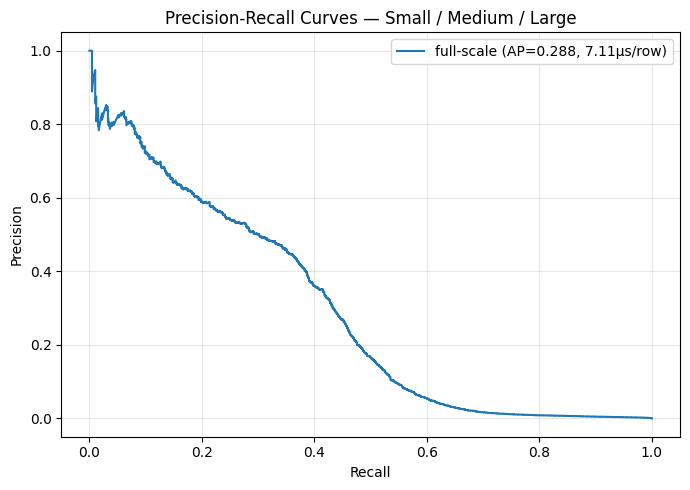


Summary (accuracy with latency):
Size       PR-AUC   Latency (s)     µs/row
------------------------------------------
full-scale   0.2884        62.530       7.11


In [5]:
# Evaluation: PR-AUC, inference latency, and PR curves for all 4 models
import time

scores_by_size = {}
results = {}

fig, ax = plt.subplots(figsize=(7, 5))

for size, model_i in trained_models.items():
    # Inference latency (average over 3 runs on full test set)
    latencies = []
    for _ in range(3):
        t0 = time.perf_counter()
        y_score_i = model_i.predict_proba(X_test)[:, 1]
        latencies.append(time.perf_counter() - t0)
    avg_lat = sum(latencies) / len(latencies)
    lat_per_row_us = avg_lat / len(X_test) * 1e6  # microseconds per row

    ap = average_precision_score(y_test, y_score_i)
    scores_by_size[size] = y_score_i
    results[size] = {'pr_auc': ap, 'latency_s': avg_lat, 'us_per_row': lat_per_row_us}

    prec, rec, _ = precision_recall_curve(y_test, y_score_i)
    ax.plot(rec, prec, label=f'{size} (AP={ap:.3f}, {lat_per_row_us:.2f}µs/row)')

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves — Small / Medium / Large')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('\nSummary (accuracy with latency):')
print(f'{"Size":<8} {"PR-AUC":>8} {"Latency (s)":>13} {"µs/row":>10}')
print('-' * 42)
for size, r in results.items():
    print(f'{size:<8} {r["pr_auc"]:>8.4f} {r["latency_s"]:>13.3f} {r["us_per_row"]:>10.2f}')


In [8]:
# Evaluate all models at alert budget (top-k by score)
def eval_at_alert_rate(y_true: pd.Series, scores: np.ndarray, rate: float = 0.001):
    n = len(scores)
    k = max(1, int(n * rate))
    order = np.argsort(scores)[::-1]
    top_idx = order[:k]
    tp = int(y_true.iloc[top_idx].sum())
    precision = tp / k
    recall = tp / int(y_true.sum()) if int(y_true.sum()) > 0 else np.nan
    return k, precision, recall

print(f'Alert rate: {ALERT_RATE*100:.3f}%\n')
print(f'{"Size":<8} {"top-k":>6} {"Prec@k":>8} {"Rec@k":>8}')
print('-' * 34)
for size, y_score_i in scores_by_size.items():
    k, p_at_k, r_at_k = eval_at_alert_rate(y_test, y_score_i, rate=ALERT_RATE)
    print(f'{size:<8} {k:>6} {p_at_k:>8.4f} {r_at_k:>8.4f}')


Alert rate: 0.100%

Size      top-k   Prec@k    Rec@k
----------------------------------
small      8795   0.0985   0.4988
medium     8795   0.1009   0.5109
large      8795   0.1037   0.5253


In [9]:
# Feature importance for large model (most expressive)
model_large = trained_models['large']
final_est = model_large[-1]
try:
    fe_names = model_large[0].get_feature_names_out()
except Exception:
    fe_names = [f'f{i}' for i in range(model_large[0].transform(X_test).shape[1])]

importances = final_est.feature_importances_
imp = (pd.DataFrame({'feature': fe_names, 'importance': importances})
            .sort_values('importance', ascending=False)
            .head(20))
display(imp)


,feature,importance
17,num__fb_tx_count,7696
20,num__fb_cross_ccy_rate,6907
9,num__acc_tx_count,6810
21,num__tb_tx_count,6444
13,num__toacc_tx_count,6088
24,num__tb_cross_ccy_rate,5547
11,num__acc_amt_recv_mean,5526
10,num__acc_amt_paid_mean,5359
14,num__toacc_amt_paid_mean,4928
18,num__fb_amt_paid_mean,4919


### Conversion to ONNX

In [6]:
%%capture
# ONNX conversion: LightGBM Pipeline
import os
import numpy as np
import onnx
import onnxruntime as rt
import skl2onnx
import onnxmltools
from skl2onnx import to_onnx, convert_sklearn, update_registered_converter
from skl2onnx.common.shape_calculator import calculate_linear_classifier_output_shapes
from onnxmltools.convert.lightgbm.operator_converters.LightGbm import convert_lightgbm
from lightgbm import LGBMClassifier

# Register LightGBM converter with skl2onnx
update_registered_converter(
    LGBMClassifier,
    'LightGbmLGBMClassifier',
    calculate_linear_classifier_output_shapes,
    convert_lightgbm,
    options={'nocl': [True, False], 'zipmap': [True, False, 'columns']},
)


In [7]:
# Convert all 4 trained pipelines to ONNX
import datetime
from skl2onnx import to_onnx
from lightgbm import LGBMClassifier
import numpy as np

ts = datetime.datetime.now().strftime("%Y-%m-%d-%H-%M-%S")

X_schema = X_train.iloc[:5].copy()
for col in numeric_features:
    X_schema[col] = X_schema[col].astype(np.float32)

onnx_paths = {}

for size, model_i in trained_models.items():
    onnx_path = f"./pipeline_lightgbm_{size}_{ts}.onnx"
    model_onnx = to_onnx(
        model_i,
        X_schema,
        target_opset={"": 15, "ai.onnx.ml": 3},
        options={LGBMClassifier: {"zipmap": False}},
    )
    with open(onnx_path, "wb") as f:
        f.write(model_onnx.SerializeToString())
    onnx_paths[size] = onnx_path
    print(f"Saved {size}: {onnx_path}")


Saved full-scale: ./pipeline_lightgbm_full-scale_2026-03-19-21-37-50.onnx


In [13]:
# Compare sklearn vs ONNX predictions for each model size
import re

X_sample = X_test.iloc[:500].copy()

def norm(s):
    return re.sub(r'[^0-9A-Za-z_]+', '_', s)

def build_onnx_inputs(sess, X_df):
    inputs = {}
    for meta in sess.get_inputs():
        name = meta.name
        src = None
        if name in X_df.columns:
            src = name
        else:
            alt = name.replace('_', ' ')
            if alt in X_df.columns:
                src = alt
            else:
                nname = norm(name)
                for c in X_df.columns:
                    if norm(c) == nname:
                        src = c
                        break
        if src is None:
            continue
        col = X_df[src].to_numpy()
        t = meta.type
        if 'tensor(float)' in t or 'tensor(double)' in t:
            col = col.astype(np.float32)
        elif 'tensor(int64)' in t or 'tensor(int)' in t:
            col = col.astype(np.int64)
        elif 'tensor(string)' in t:
            col = col.astype(str).astype(object)
        inputs[name] = col.reshape((-1, 1))
    missing = [m.name for m in sess.get_inputs() if m.name not in inputs]
    if missing:
        raise ValueError(f'Missing required ONNX inputs: {missing}')
    return inputs

for size, onnx_path in onnx_paths.items():
    print(f'\n--- {size} ---')
    model_i = trained_models[size]
    sk_pred  = model_i.predict(X_sample)
    sk_proba = model_i.predict_proba(X_sample)[:, 1]

    sess = rt.InferenceSession(onnx_path, providers=['CPUExecutionProvider'])
    inputs = build_onnx_inputs(sess, X_sample)
    pred_onx = sess.run(None, inputs)

    onx_pred  = pred_onx[0]
    onx_proba = pred_onx[1][:, 1] if len(pred_onx) > 1 else None

    match = (sk_pred == onx_pred).mean()
    print(f'  Prediction agreement: {match*100:.1f}%')
    if onx_proba is not None:
        max_diff = float(np.abs(sk_proba - onx_proba).max())
        print(f'  Max proba diff (sklearn vs ONNX): {max_diff:.6f}')



--- small ---
  Prediction agreement: 100.0%
  Max proba diff (sklearn vs ONNX): 0.000000

--- medium ---
  Prediction agreement: 100.0%
  Max proba diff (sklearn vs ONNX): 0.000000

--- large ---
  Prediction agreement: 100.0%
  Max proba diff (sklearn vs ONNX): 0.000000
